In [1]:
import os
import sys
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import Rbf
import umap

# Add project root to path
sys.path.append(os.path.abspath('../../'))
from BWM.ScriptsandFunctions.bwm_functions import *

# Set global plotting parameters
plt.rcParams["axes.grid"] = False
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 8,
    'axes.titlesize': 9,
    'axes.labelsize': 8,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 8,
    'figure.titlesize': 10
})


In [2]:
# 1. Configuration
selected_eids = ['6274dda8-3a59-4aa1-95f8-a8a549c46a26', '5d01d14e-aced-4465-8f8e-9a1c674f62ec'] # Two EIDs
directory_path = '../Data2'
event = 'stimOn_times'
conditions = ['choice']


In [3]:
# 2. Helper Functions
def iso_ae_preprocessing(pseudo_response_tensor):
    """
    Preprocess neural responses intro response matrix (n x kt) for autoencoder.
    """
    response_tensor = np.mean(pseudo_response_tensor, axis=0)
    # Z-score and reshape
    response_tensor_norm = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    response_matrix = response_tensor_norm.reshape(-1, response_tensor_norm.shape[2])
    X_transposed = response_matrix.T
    return X_transposed

def trial_variability(x):
    z = (x-np.mean(x,axis=(0,1,2)))/np.std(x,axis=(0,1,2))
    return (
        np.mean(np.std(z, axis=0),axis=(0,1)))


In [4]:
# 3. Load & Process Data
all_results = []

for eid in selected_eids:
    result = get_eid_response_matrix(
        eid, directory_path, event, conditions,
        n_pseudo=25,
        threshold = 0,
        filter_significant=False,
        n_steps=100, step=0.01 , sigma=2,
    )
    
    pseudo_response_tensor, common_conditions, beryl_regions, cosmos_regions, cluster_ids = result
    print(f"Loaded data for {eid}: {pseudo_response_tensor.shape}")
    
    # 4. Preprocessing & DensMAP Projection
    variability = trial_variability(pseudo_response_tensor)
    pseudo_response_tensor = pseudo_response_tensor[:,:,:,variability<1]
    
    X_input = iso_ae_preprocessing(pseudo_response_tensor)
    
    reducer = umap.UMAP(densmap=True, dens_lambda = 2, min_dist=  .1, n_neighbors=500)
    embedding = reducer.fit_transform(X_input)
    
    # 5. Grid Setup
    avg_response = np.mean(pseudo_response_tensor, axis=0)
    nx, ny = 100, 100
    x_grid = np.linspace(embedding[:, 0].min() - 0.5, embedding[:, 0].max() + 0.5, nx)
    y_grid = np.linspace(embedding[:, 1].min() - 0.5, embedding[:, 1].max() + 0.5, ny)
    xx, yy = np.meshgrid(x_grid, y_grid)
    
    all_results.append({
        'eid': eid,
        'embedding': embedding,
        'avg_response': avg_response,
        'x_grid': x_grid,
        'y_grid': y_grid,
        'xx': xx,
        'yy': yy
    })


Loaded data for 6274dda8-3a59-4aa1-95f8-a8a549c46a26: (25, 2, 100, 1587)


/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_51594/1776381799.py:14: RuntimeWarning: invalid value encountered in divide
  z = (x-np.mean(x,axis=(0,1,2)))/np.std(x,axis=(0,1,2))


Loaded data for 5d01d14e-aced-4465-8f8e-9a1c674f62ec: (25, 2, 100, 1288)


/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_51594/1776381799.py:14: RuntimeWarning: invalid value encountered in divide
  z = (x-np.mean(x,axis=(0,1,2)))/np.std(x,axis=(0,1,2))


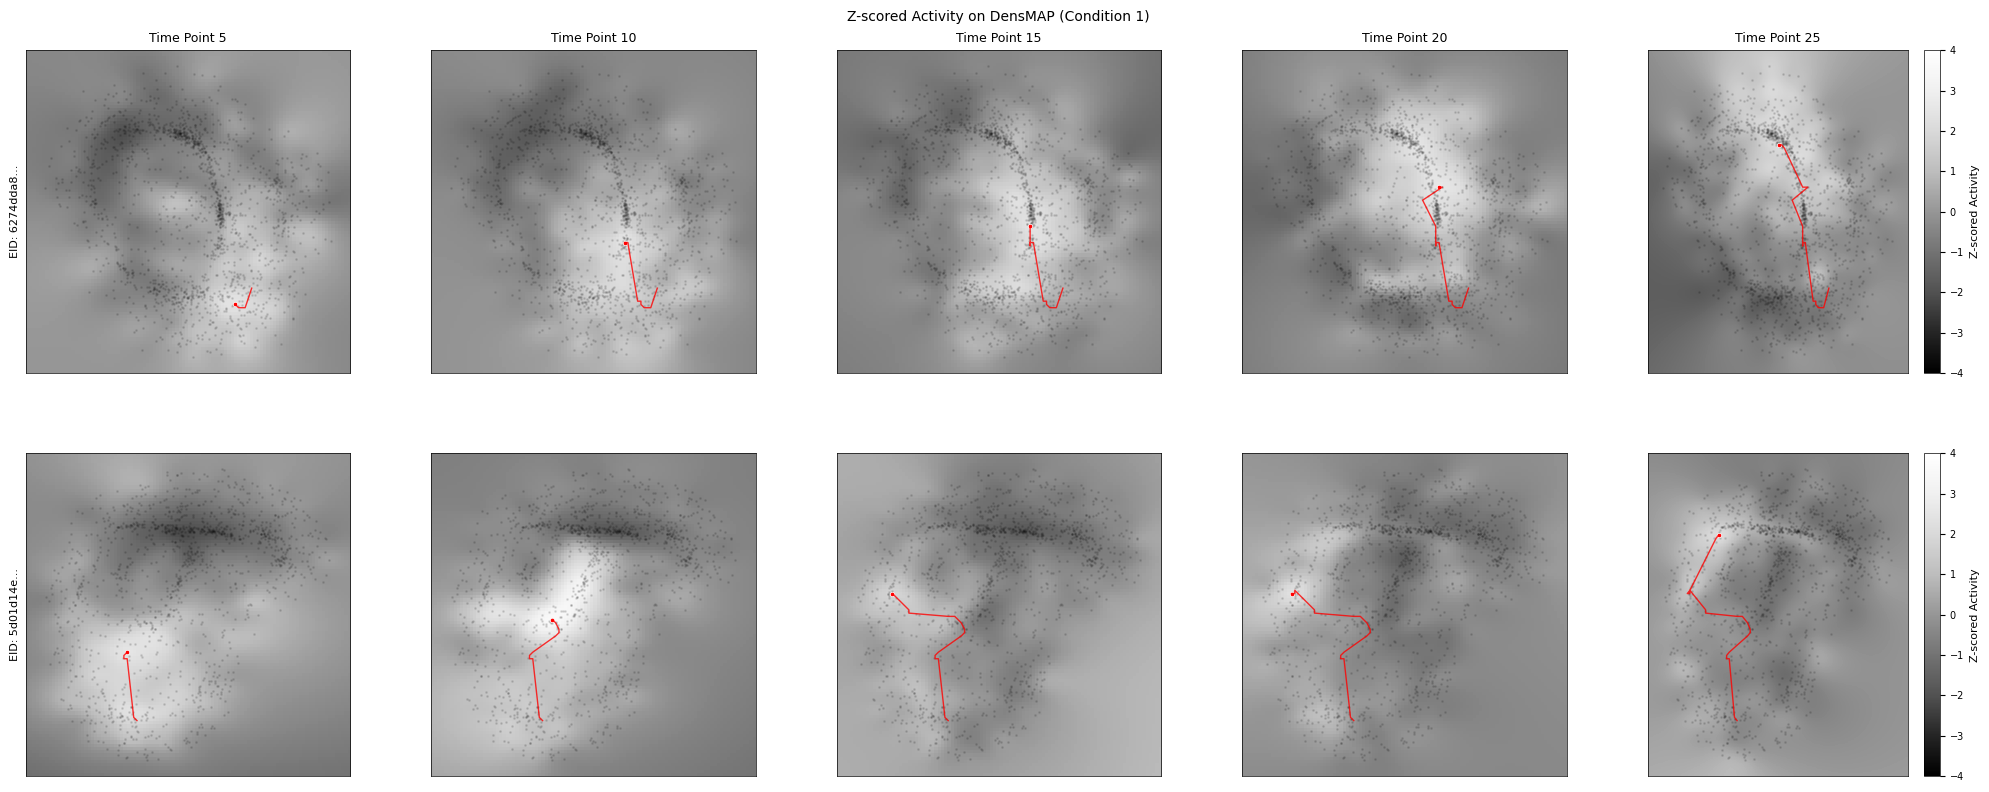

In [5]:
# 6. Activity Visualization (5 time points, 2 EIDs)
# Select condition 0 and 5 time points
cond_idx = 1
time_points = [5, 10, 15, 20, 25]
n_time_points = len(time_points)
n_eids = len(selected_eids)

fig, axes = plt.subplots(n_eids, n_time_points, figsize=(20, 4 * n_eids))

for row, res in enumerate(all_results):
    embedding = res['embedding']
    avg_response = res['avg_response']
    x_grid = res['x_grid']
    y_grid = res['y_grid']
    xx = res['xx']
    yy = res['yy']
    eid = res['eid']
    
    # Z-score the activity for the selected condition
    activity_cond = avg_response[cond_idx] # (time, neurons)
    activity_mean = np.mean(activity_cond, axis=0, keepdims=True)
    activity_std = np.std(activity_cond, axis=0, keepdims=True)
    activity_zscored = (activity_cond - activity_mean) / (activity_std + 1e-8)
    
    peak_locations = []
    
    # First pass: find all peak locations for this EID
    for t in range(activity_zscored.shape[0]):
        z_t = activity_zscored[t, :]
        rbf_t = Rbf(embedding[:, 0], embedding[:, 1], z_t, function='multiquadric', smooth=4)
        z_grid_t = rbf_t(xx, yy)
        
        # Find peak location in the grid
        max_idx = np.unravel_index(np.argmax(z_grid_t), z_grid_t.shape)
        peak_x = xx[max_idx]
        peak_y = yy[max_idx]
        peak_locations.append((peak_x, peak_y))
    
    peak_locations = np.array(peak_locations)
    
    for i, t in enumerate(time_points):
        ax = axes[row, i]
        # Activity at time point t
        z_t = activity_zscored[t, :]
        
        # Fit RBF for this time point
        rbf_t = Rbf(embedding[:, 0], embedding[:, 1], z_t, function='multiquadric', smooth=4)
        
        # Interpolate on the grid
        z_grid_t = rbf_t(xx, yy)
        
        # Plot
        im = ax.imshow(z_grid_t, extent=(x_grid.min(), x_grid.max(), y_grid.min(), y_grid.max()), 
                           origin='lower', cmap='Greys_r', aspect='auto', alpha=1,
                           vmin=-4, vmax=4) # Fixed scale for comparison
        ax.scatter(embedding[:, 0], embedding[:, 1], c='black', s=1, alpha=0.1)
        
        # Plot the trace of peak locations up to time point t
        ax.plot(peak_locations[:t+1, 0], peak_locations[:t+1, 1], color='red', linewidth=1, alpha=0.8)
        ax.scatter(peak_locations[t, 0], peak_locations[t, 1], color='red', s=10, edgecolors='white', linewidth=0.5)
        
        if row == 0:
            ax.set_title(f'Time Point {t}')
        if i == 0:
            ax.set_ylabel(f'EID: {eid[:8]}...')
        ax.set_xticks([])
        ax.set_yticks([])
        if i == n_time_points - 1:
            plt.colorbar(im, ax=ax, label='Z-scored Activity')

plt.suptitle(f'Z-scored Activity on DensMAP (Condition {cond_idx})')
plt.tight_layout()
plt.subplots_adjust(wspace=0.25, hspace=0.25)
os.makedirs('../Figures', exist_ok=True)
plt.savefig(f'../Figures/ZScored_Activity_DensMAP_Cond{cond_idx}.png', dpi=300, bbox_inches='tight')
plt.show()


In [56]:
directory_path='../Data2'
eids = [d for d in os.listdir(directory_path) if os.path.isdir(os.path.join(directory_path, d))]
result = get_region_response_matrix(
                region=['CP'],
                eids=eids,
                directory_path=directory_path,
                event="stimOn_times",
                conditions=['choice'],
                n_pseudo=25,
                threshold=1,
                std_above=5,
                std_below=5,
                filter_significant=False,
                n_steps=100,
                step=0.01,
                sigma=2,
                mapping='Beryl'
            )
pseudo_response_tensor =result[0]

Aggregating ['CP'] responses across 459 EIDs...


Processing EIDs: 100%|██████████| 459/459 [03:42<00:00,  2.07it/s]

Final conditions count: 2
Total neurons collected: 11288


Fitting densmap
Condition 0, Time 5
Condition 0, Time 20
Condition 0, Time 30
Condition 0, Time 40
Condition 0, Time 50
Condition 1, Time 5
Condition 1, Time 20
Condition 1, Time 30
Condition 1, Time 40
Condition 1, Time 50


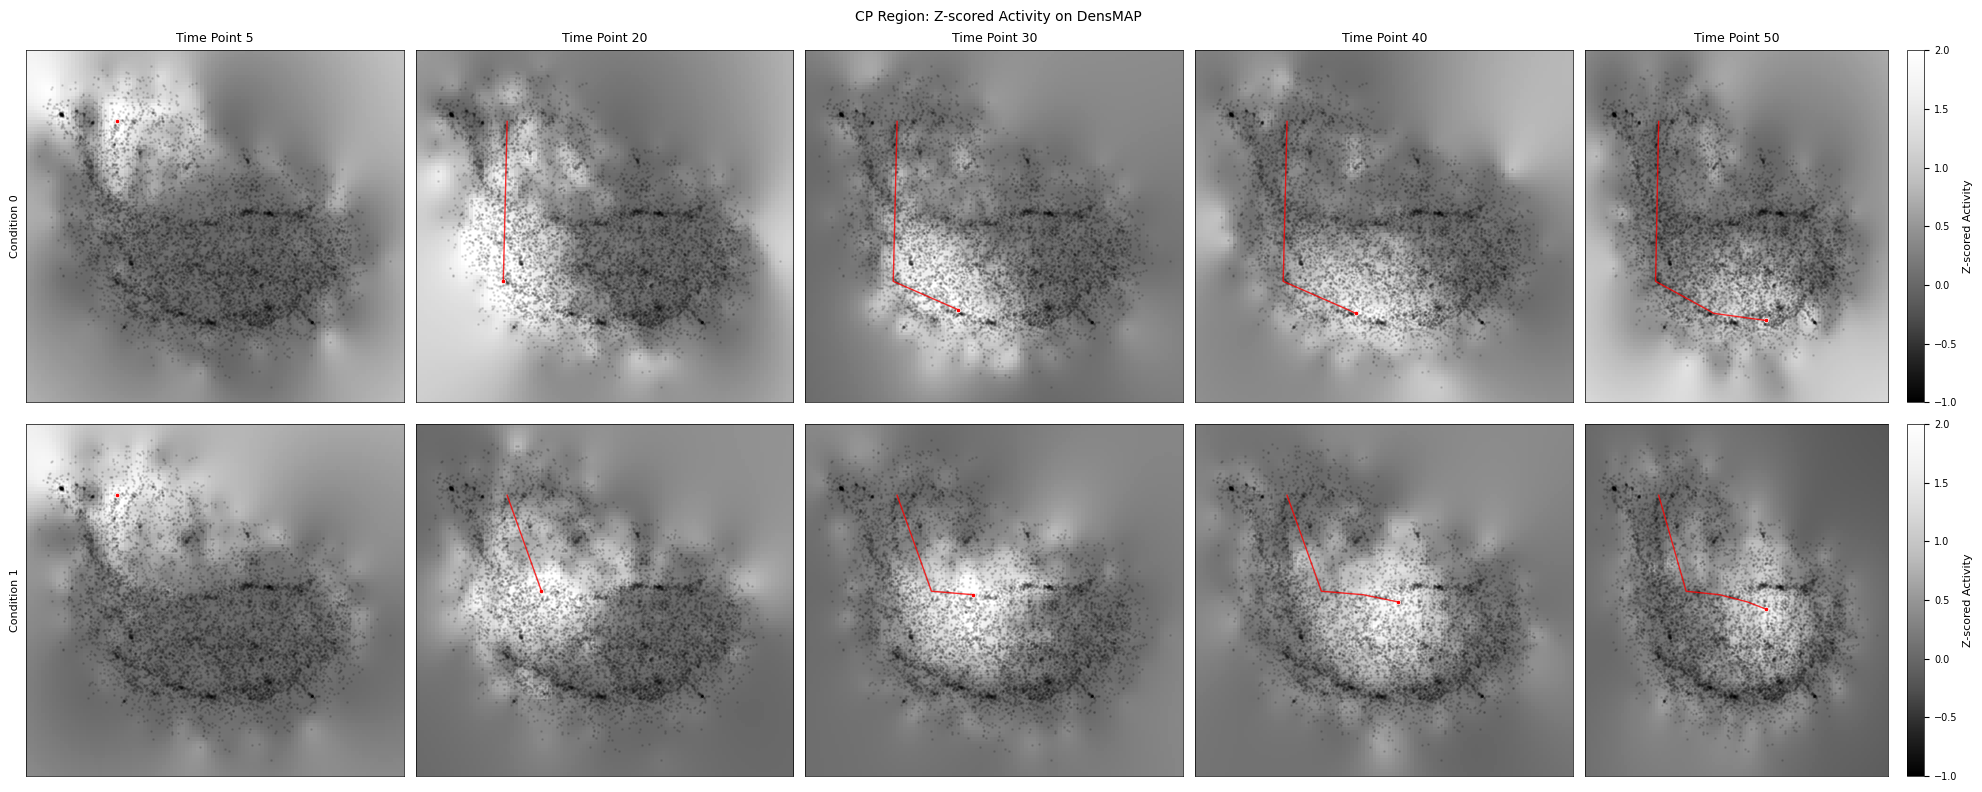

In [82]:
# 7. CP Data Activity Visualization
# pseudo_response_tensor = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/ResponseData/CP_pseudo_responses.npy')
#pseudo_response_tensor = pseudo_response_tensor[:,:,:,np.mean(pseudo_response_tensor,axis=(0,1,2))<15]

# Preprocessing CP data
variability = trial_variability(pseudo_response_tensor)
pseudo_response_tensor = pseudo_response_tensor[:,:,:,variability<.7]
X_input_cp = iso_ae_preprocessing(pseudo_response_tensor)

# DensMAP Projection for CP
print('Fitting densmap')
# reducer_cp = umap.UMAP(densmap=True, dens_lambda=2,n_neighbors=50)
# embedding_cp = reducer_cp.fit_transform(X_input_cp)

# Grid Setup for CP
avg_response_cp = np.mean(pseudo_response_tensor, axis=0)
nx, ny = 100, 100
x_grid_cp = np.linspace(embedding_cp[:, 0].min() - 0.5, embedding_cp[:, 0].max() + 0.5, nx)
y_grid_cp = np.linspace(embedding_cp[:, 1].min() - 0.5, embedding_cp[:, 1].max() + 0.5, ny)
xx_cp, yy_cp = np.meshgrid(x_grid_cp, y_grid_cp)

# Select condition and time points
time_points = [5,20,30,40,50]
n_time_points = len(time_points)
n_conditions = 2

fig, axes = plt.subplots(n_conditions, n_time_points, figsize=(20, 8))

# Z-score the activity using data from both conditions
activity_mean = np.mean(avg_response_cp, axis=(0, 1), keepdims=True)
activity_std = np.std(avg_response_cp, axis=(0, 1), keepdims=True)

for cond_idx in range(n_conditions):
    activity_zscored = (avg_response_cp[cond_idx] - activity_mean[0]) / (activity_std[0] + 1e-8)
    activity_zscored = torch.nn.functional.leaky_relu(torch.FloatTensor(activity_zscored)).numpy()

    peak_locations = []
    for i, t in enumerate(time_points):
        print(f"Condition {cond_idx}, Time {t}")
        ax = axes[cond_idx, i]
        z_t = activity_zscored[t, :]
        rbf_t = Rbf(embedding_cp[:, 0], embedding_cp[:, 1], z_t, function='multiquadric', smooth=10)
        z_grid_t = rbf_t(xx_cp, yy_cp)

        # Find peak location in the grid
        max_idx = np.unravel_index(np.argmax(z_grid_t), z_grid_t.shape)
        peak_locations.append((xx_cp[max_idx], yy_cp[max_idx]))
        current_peaks = np.array(peak_locations)

        im = ax.imshow(z_grid_t, extent=(x_grid_cp.min(), x_grid_cp.max(), y_grid_cp.min(), y_grid_cp.max()),
                           origin='lower', cmap='Greys_r', aspect='auto', vmin=-1, vmax=2)
        ax.scatter(embedding_cp[:, 0], embedding_cp[:, 1], c='black', s=1, alpha=0.1)

        # Plot the trace of peak locations for the selected time points
        ax.plot(current_peaks[:, 0], current_peaks[:, 1], color='red', linewidth=1, alpha=0.8)
        ax.scatter(current_peaks[-1, 0], current_peaks[-1, 1], color='red', s=10, edgecolors='white', linewidth=0.5)

        if cond_idx == 0:
            ax.set_title(f'Time Point {t}')
        if i == 0:
            ax.set_ylabel(f'Condition {cond_idx}')
        ax.set_xticks([])
        ax.set_yticks([])
        if i == n_time_points - 1:
            plt.colorbar(im, ax=ax, label='Z-scored Activity')

plt.suptitle(f'CP Region: Z-scored Activity on DensMAP')
plt.tight_layout()
plt.savefig('../Figures/CP_Activity_Visualization.png', dpi=300, bbox_inches='tight')
plt.show()
